# Experiment: Principal Component Analysis (PCA) on Wine Dataset

**Aim:** Apply PCA on a high-dimensional dataset and compare:
1. Number of features before and after PCA
2. Visualization of reduced dimensions
3. Impact on classification performance

**Dataset:** Wine Quality (red + white) – 11 chemical properties, target = wine `type`.

## Step 1: Load the dataset

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('wine_quality_merged.csv')   # keep the CSV in the same folder as this notebook
print("Shape:", df.shape)
df.head()

Shape: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [32]:
print(df['type'].value_counts())
print("Missing values:", df.isnull().sum().sum())

type
white    4898
red      1599
Name: count, dtype: int64
Missing values: 0


## Step 2: Select input features and target
- **Features (X):** the 11 chemical properties (we leave out `quality` and `type`)
- **Target (y):** `type`

In [33]:
features = ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
            'chlorides', 'free sulfur dioxide', 'total sulfur dioxide',
            'density', 'pH', 'sulphates', 'alcohol']

X = df[features]
y = df['type']
print("Number of features:", X.shape[1])

Number of features: 11


## Step 3: Encode `type`  (Red → 0, White → 1)

In [34]:
y = y.map({'red': 0, 'white': 1})
print(y.value_counts())

type
1    4898
0    1599
Name: count, dtype: int64


## Step 4: Split into training and testing sets
`stratify=y` keeps the same red/white ratio in both train and test sets.

In [35]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (5197, 11)  Test: (1300, 11)


## Step 5: Standardize the features
PCA depends on variance, so features with large numeric ranges (like *total sulfur dioxide*) would dominate
if we did not scale. We **fit the scaler on training data only** and just transform the test data,
so the test set stays truly "unseen".

In [36]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Step 6: Logistic Regression WITHOUT PCA (baseline, 11 features)

In [37]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate(model, Xtr, Xte, name):
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    res = {'Model': name,
           'Features': Xtr.shape[1],
           'Accuracy': accuracy_score(y_test, pred),
           'Precision': precision_score(y_test, pred),
           'Recall': recall_score(y_test, pred),
           'F1-score': f1_score(y_test, pred)}
    return res

res_orig = evaluate(LogisticRegression(max_iter=1000), X_train_scaled, X_test_scaled, 'Original (no PCA)')
for k, v in res_orig.items():
    print(f"{k:10}: {v:.4f}" if isinstance(v, float) else f"{k:10}: {v}")

Model     : Original (no PCA)
Features  : 11
Accuracy  : 0.9938
Precision : 0.9969
Recall    : 0.9949
F1-score  : 0.9959


## Step 7: Apply PCA – reduce 11 features → 2 principal components

In [38]:
from sklearn.decomposition import PCA

pca2 = PCA(n_components=2)
X_train_pca2 = pca2.fit_transform(X_train_scaled)
X_test_pca2 = pca2.transform(X_test_scaled)

print("Before PCA:", X_train_scaled.shape[1], "features")
print("After PCA :", X_train_pca2.shape[1], "features")
print("Variance explained by PC1 and PC2:", pca2.explained_variance_ratio_.round(4))
print("Total variance kept by 2 components: {:.2%}".format(pca2.explained_variance_ratio_.sum()))

Before PCA: 11 features
After PCA : 2 features
Variance explained by PC1 and PC2: [0.2762 0.2268]
Total variance kept by 2 components: 50.29%


## Step 8: Visualize the reduced data (PC1 vs PC2)

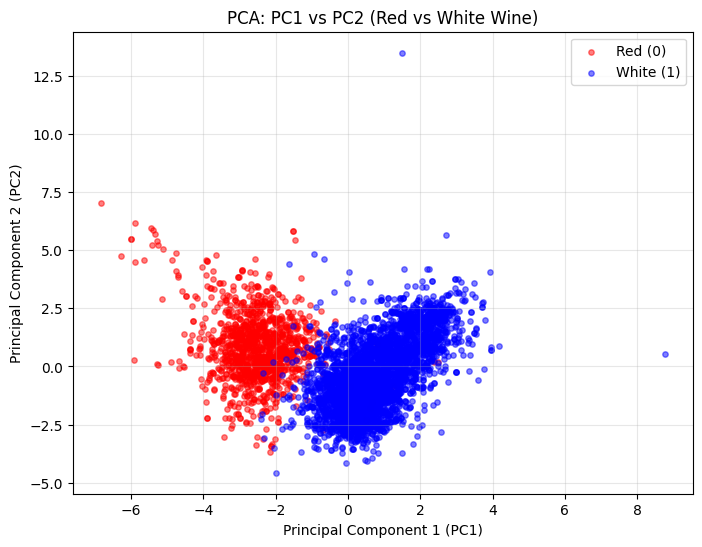

In [39]:
plt.figure(figsize=(8, 6))
plt.scatter(X_train_pca2[y_train == 0, 0], X_train_pca2[y_train == 0, 1],
            c='red', alpha=0.5, s=15, label='Red (0)')
plt.scatter(X_train_pca2[y_train == 1, 0], X_train_pca2[y_train == 1, 1],
            c='blue', alpha=0.5, s=15, label='White (1)')
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.title('PCA: PC1 vs PC2 (Red vs White Wine)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Observation:** Red and white wines form two mostly separate groups, with a small overlap.
So just 2 components already capture much of what distinguishes the two types.

## Step 9: Choose a suitable number of components
First fit PCA with all 11 components and look at the **explained variance**. Then pick the smallest number of
components that keeps most of the information. A common rule of thumb is 90% of the variance; using fewer
components is a trade-off between compression and information kept.

In [40]:
pca_full = PCA(n_components=11)
pca_full.fit(X_train_scaled)

var_ratio = pca_full.explained_variance_ratio_
cum_var = np.cumsum(var_ratio)

var_table = pd.DataFrame({
    'Component': [f'PC{i}' for i in range(1, 12)],
    'Explained Variance': var_ratio.round(4),
    'Cumulative Variance': cum_var.round(4)})
var_table

,Component,Explained Variance,Cumulative Variance
0,PC1,0.2762,0.2762
1,PC2,0.2268,0.5029
2,PC3,0.1409,0.6438
3,PC4,0.0883,0.7321
4,PC5,0.0657,0.7978
5,PC6,0.0553,0.8531
6,PC7,0.0477,0.9009
7,PC8,0.0452,0.9461
8,PC9,0.0303,0.9764
9,PC10,0.0206,0.9970


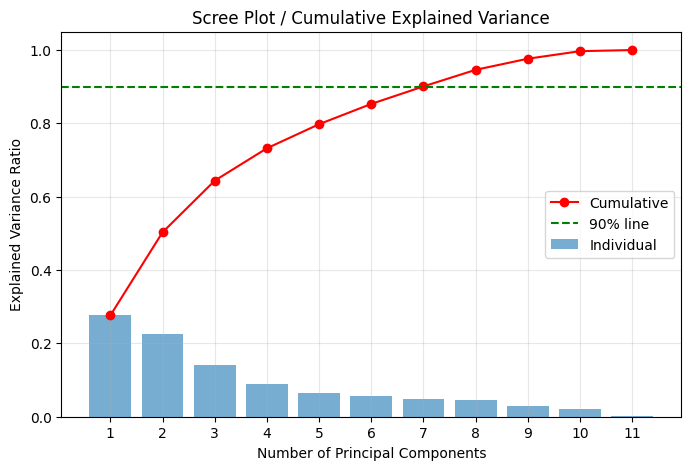

Components needed for 90% variance: 7


In [41]:
plt.figure(figsize=(8, 5))
plt.bar(range(1, 12), var_ratio, alpha=0.6, label='Individual')
plt.plot(range(1, 12), cum_var, 'o-', color='red', label='Cumulative')
plt.axhline(0.90, color='green', linestyle='--', label='90% line')
plt.xlabel('Number of Principal Components')
plt.ylabel('Explained Variance Ratio')
plt.title('Scree Plot / Cumulative Explained Variance')
plt.xticks(range(1, 12))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Components needed for 90% variance:", np.argmax(cum_var >= 0.90) + 1)

In [42]:
n_comp = 7   # chosen number of components (can be changed after looking at the plot above)

pca5 = PCA(n_components=n_comp)
X_train_pca5 = pca5.fit_transform(X_train_scaled)
X_test_pca5 = pca5.transform(X_test_scaled)

print(f"Features before PCA: {X_train_scaled.shape[1]}")
print(f"Features after PCA : {X_train_pca5.shape[1]}")
print("Variance retained with {} components: {:.2%}".format(n_comp, pca5.explained_variance_ratio_.sum()))

Features before PCA: 11
Features after PCA : 7
Variance retained with 7 components: 90.09%


## Step 10: Logistic Regression on PCA-transformed data

In [43]:
res_pca5 = evaluate(LogisticRegression(max_iter=1000), X_train_pca5, X_test_pca5, f'PCA ({n_comp} components)')
res_pca2 = evaluate(LogisticRegression(max_iter=1000), X_train_pca2, X_test_pca2, 'PCA (2 components)')

for r in (res_pca5, res_pca2):
    print(r['Model'])
    for k in ['Features', 'Accuracy', 'Precision', 'Recall', 'F1-score']:
        v = r[k]
        print(f"   {k:10}: {v:.4f}" if isinstance(v, float) else f"   {k:10}: {v}")

PCA (7 components)
   Features  : 7
   Accuracy  : 0.9877
   Precision : 0.9939
   Recall    : 0.9898
   F1-score  : 0.9918
PCA (2 components)
   Features  : 2
   Accuracy  : 0.9869
   Precision : 0.9918
   Recall    : 0.9908
   F1-score  : 0.9913


## Step 11: Compare the results

In [44]:
results = pd.DataFrame([res_orig, res_pca2, res_pca5]).set_index('Model')
results.round(4)

,Features,Accuracy,Precision,Recall,F1-score
Model,,,,,
Original (no PCA),11,0.9938,0.9969,0.9949,0.9959
PCA (2 components),2,0.9869,0.9918,0.9908,0.9913
PCA (7 components),7,0.9877,0.9939,0.9898,0.9918
